# Step 5: Discovering day types with clustering

**Project:** Learning What "Normal" Looks Like: Clustering-Based Contextual Anomaly Detection in Bike Sharing

This is the core of the project: let the data decide which kinds of days exist, instead of assuming them from calendar labels. Four clustering methods from the course are applied to the day shapes and compared (Clustering lecture):

| Method | Paradigm | Slides |
| --- | --- | --- |
| k-means | partitioning | 6 to 22 |
| Agglomerative (hierarchical) clustering | hierarchical | 24 to 29, 112 |
| Gaussian Mixture Model (GMM) | model-based | 54 to 82 |
| DBSCAN | density-based | 84 to 85 |

The number of clusters is chosen with the elbow method, the silhouette score and BIC (Slides 86 to 108), and the final clusters are checked for whether they make sense (expert knowledge, Slide 114).

**Input:** the first 4 principal components of the day shapes for all riders (`pca_scores_all.csv`, 90% of the variance; Step 4). Clustering on 4 components instead of 24 hours removes noise and makes distances more meaningful.

**Important for a fair evaluation:** the clusters are chosen using these internal criteria only. The verified events list is **not** used here; it is used only in Step 7.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})
SEED = 0

Z = pd.read_csv("pca_scores_all.csv", index_col="dteday", parse_dates=True)
shape = pd.read_csv("shape_all.csv", index_col="dteday", parse_dates=True)
info = pd.read_csv("day_info.csv", index_col="dteday", parse_dates=True)
level = pd.read_csv("level.csv", index_col="dteday", parse_dates=True)
X = Z.values
print("Clustering input:", X.shape, "(days x principal components)")

Clustering input: (731, 4) (days x principal components)


## 1. k-means: elbow and silhouette

k-means is run for k = 2 to 10 (20 random starts each, so the result does not depend on one lucky start).

- **Elbow method:** the within-cluster sum of squares always falls as k grows; the "elbow" is where adding clusters stops helping much.
- **Silhouette score:** how much closer each day is to its own cluster than to the nearest other cluster (from -1 to 1; higher is better).

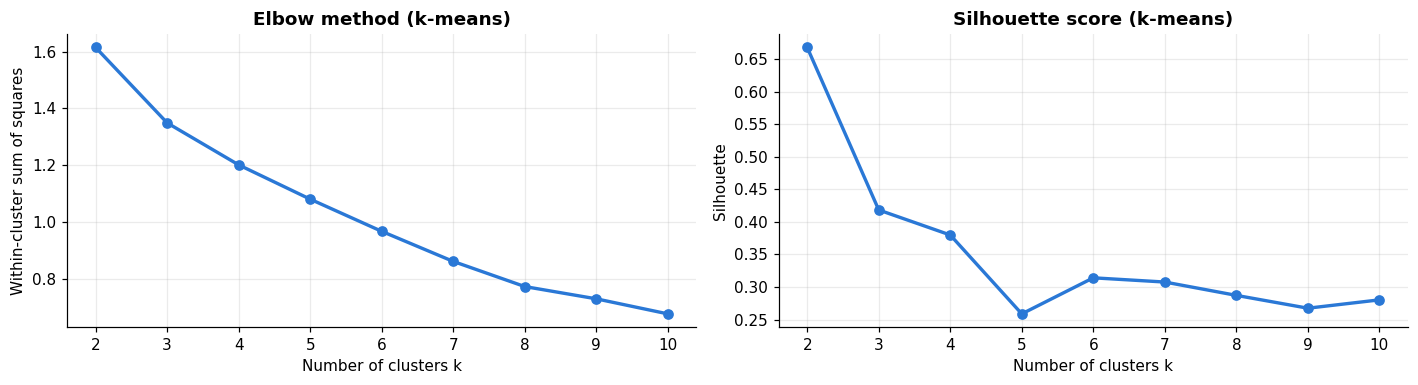

,inertia,silhouette,cluster sizes
k,,,
2,1.615,0.668,"[492, 239]"
3,1.349,0.418,"[336, 238, 157]"
4,1.201,0.380,"[257, 237, 208, 29]"
5,1.080,0.259,"[256, 213, 126, 111, 25]"
6,0.966,0.314,"[340, 134, 109, 98, 29, 21]"
7,0.860,0.308,"[312, 125, 123, 105, 29, 28, 9]"
8,0.772,0.287,"[218, 164, 124, 102, 71, 31, 13, 8]"
9,0.728,0.267,"[221, 160, 81, 81, 77, 68, 23, 12, 8]"
10,0.675,0.280,"[213, 159, 91, 87, 71, 49, 23, 20, 12, 6]"


In [2]:
ks = range(2, 11)
km_models = {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X) for k in ks}
km_table = pd.DataFrame({
    "inertia": [km_models[k].inertia_ for k in ks],
    "silhouette": [silhouette_score(X, km_models[k].labels_) for k in ks],
    "cluster sizes": [sorted(np.bincount(km_models[k].labels_), reverse=True) for k in ks],
}, index=pd.Index(ks, name="k"))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(ks, km_table.inertia, color=BLUE, linewidth=2.2, marker="o")
axes[0].set(title="Elbow method (k-means)", xlabel="Number of clusters k", ylabel="Within-cluster sum of squares")
axes[1].plot(ks, km_table.silhouette, color=BLUE, linewidth=2.2, marker="o")
axes[1].set(title="Silhouette score (k-means)", xlabel="Number of clusters k", ylabel="Silhouette")
fig.tight_layout()
plt.show()
km_table.round(3)

**Result.** The silhouette score is clearly highest at **k = 2** (about 0.67), and the clusters are then working days versus days off. The elbow is not sharp: the curve keeps bending gradually up to about k = 4 or 5.

So there is one very strong split in the data (the PC1 split from Step 4), and possibly finer structure inside it that is less well separated. The silhouette score favours well-separated clusters, so it cannot see overlapping sub-groups well. The next methods look at this from other angles.

## 2. Hierarchical clustering: dendrogram and linkage

Agglomerative clustering merges the two closest clusters step by step. How "closest" is measured is the **linkage** (Slide 26):

- **Ward:** merges the pair that increases the within-cluster variance least (similar to k-means);
- **average** and **complete:** use the average or the largest distance between members.

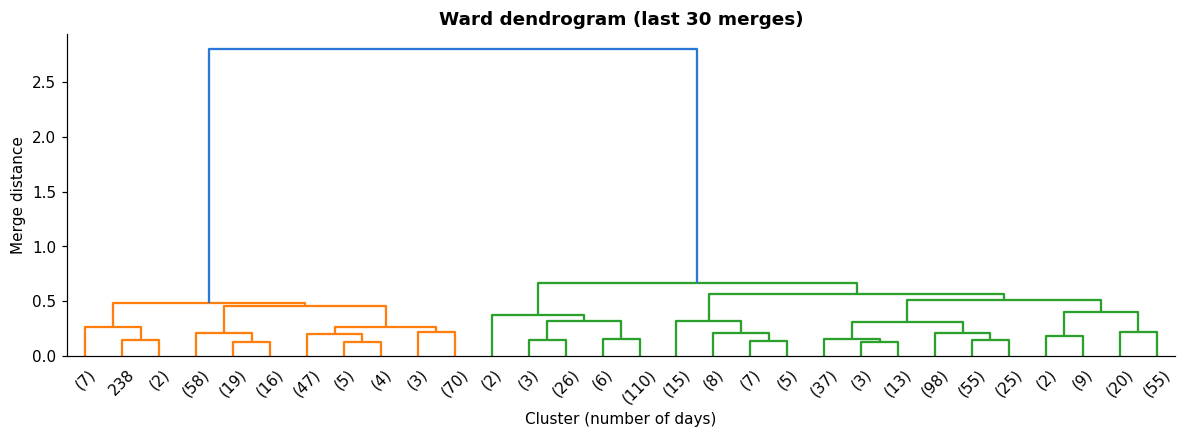

silhouette                cluster sizes
linkage  k                                         
ward     2       0.660                   [499, 232]
         3       0.333              [352, 232, 147]
         4       0.356          [317, 232, 147, 35]
         5       0.349      [232, 231, 147, 86, 35]
         6       0.345  [231, 222, 147, 86, 35, 10]
average  2       0.571                     [729, 2]
         3       0.515                  [727, 2, 2]
         4       0.441               [723, 4, 2, 2]
         5       0.653          [491, 232, 4, 2, 2]
         6       0.642       [491, 231, 4, 2, 2, 1]
complete 2       0.065                    [702, 29]
         3       0.065                 [700, 29, 2]
         4       0.479            [446, 254, 29, 2]
         5       0.484        [428, 254, 29, 18, 2]
         6       0.353    [428, 218, 36, 29, 18, 2]

In [3]:
fig, ax = plt.subplots(figsize=(13, 3.8))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=30, ax=ax,
           color_threshold=None, above_threshold_color=BLUE, show_leaf_counts=True)
ax.set(title="Ward dendrogram (last 30 merges)", xlabel="Cluster (number of days)", ylabel="Merge distance")
ax.grid(False)
plt.show()

rows = []
for method in ["ward", "average", "complete"]:
    for k in range(2, 7):
        lab = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        rows.append({"linkage": method, "k": k, "silhouette": silhouette_score(X, lab),
                     "cluster sizes": sorted(np.bincount(lab), reverse=True)})
pd.DataFrame(rows).set_index(["linkage", "k"]).round(3)

**Result.**

- **Ward** gives the same picture as k-means: one big split into about 500 and 230 days, then smaller groups split off (for example a group of about 35 days at k = 4).
- **Average linkage** keeps two big clusters and puts **single days or pairs of days into their own tiny clusters**. Its silhouette is high, but only because those tiny clusters are so far from everything else. These isolated days are exactly the kind of day the project is looking for: days that look like no other day. They are passed on to anomaly detection (Step 7), not treated as day types.

## 3. Gaussian Mixture Model: BIC

A GMM assumes each day type is a Gaussian "cloud" with its own centre, size and orientation. It is fitted with Expectation Maximisation (Slides 56 to 68), and the number of components is chosen with **BIC** (Slides 90 to 108): BIC rewards fitting the data well but penalises extra parameters, so the lowest BIC is the best trade-off.

Four covariance types are compared: `full` lets each cloud have any shape and orientation, while `diag`, `tied` and `spherical` are more restricted.

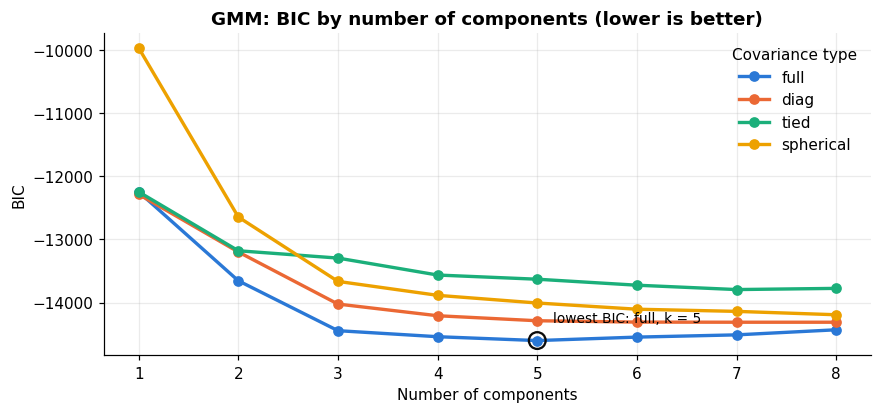

,full,diag,tied,spherical
components,,,,
1,-12246.0,-12285.0,-12246.0,-9965.0
2,-13654.0,-13198.0,-13179.0,-12644.0
3,-14445.0,-14023.0,-13295.0,-13664.0
4,-14541.0,-14208.0,-13563.0,-13885.0
5,-14602.0,-14288.0,-13630.0,-14006.0
6,-14547.0,-14309.0,-13724.0,-14105.0
7,-14511.0,-14311.0,-13793.0,-14139.0
8,-14431.0,-14311.0,-13775.0,-14193.0


In [4]:
gmm_ks = range(1, 9)
bic = pd.DataFrame({
    ct: [GaussianMixture(k, covariance_type=ct, n_init=5, random_state=SEED).fit(X).bic(X) for k in gmm_ks]
    for ct in ["full", "diag", "tied", "spherical"]}, index=pd.Index(gmm_ks, name="components"))

fig, ax = plt.subplots(figsize=(9, 3.8))
for ct, color in zip(bic.columns, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(bic.index, bic[ct], color=color, linewidth=2.2, marker="o", label=ct)
best_k = int(bic["full"].idxmin())
ax.scatter([best_k], [bic.loc[best_k, "full"]], s=120, facecolors="none", edgecolors="#0b0b0b", linewidths=1.5, zorder=5)
ax.annotate(f"lowest BIC: full, k = {best_k}", (best_k, bic.loc[best_k, "full"]), xytext=(10, 12),
            textcoords="offset points", fontsize=9)
ax.set(title="GMM: BIC by number of components (lower is better)", xlabel="Number of components", ylabel="BIC")
ax.legend(frameon=False, title="Covariance type")
plt.show()
bic.round(0)

In [5]:
# Is the 5-component solution stable? Refit with 10 different random seeds and compare
# each result with the first one (adjusted Rand index: 1 = identical clusters).
fits = [GaussianMixture(best_k, covariance_type="full", n_init=10, random_state=s).fit(X) for s in range(10)]
labels_by_seed = [f.predict(X) for f in fits]
ari = [adjusted_rand_score(labels_by_seed[0], lab) for lab in labels_by_seed]
print("Agreement with seed 0 (adjusted Rand index):", np.round(ari, 2))
print(f"Median agreement: {np.median(ari):.2f}")

Agreement with seed 0 (adjusted Rand index): [1.   0.99 0.96 1.   0.96 0.84 0.97 1.   1.   0.98]
Median agreement: 0.99


**Result.** BIC is lowest for **5 components with full covariance**, and refitting with different random seeds gives almost the same clusters (adjusted Rand index around 0.96 to 1.00 in most runs). So the 5-cluster structure is a stable property of the data, not an accident of initialisation.

## 4. DBSCAN: dense regions and noise

DBSCAN (Slides 84 to 85) does not need the number of clusters. It needs two parameters:

- `min_samples`: how many neighbours a day needs to be in a dense region. A common rule is twice the number of dimensions: 2 x 4 = 8.
- `eps`: the neighbourhood radius. It is read from the **k-distance plot**: the distance from each day to its 8th nearest neighbour, sorted. The bend in the curve separates days inside dense regions from isolated days.

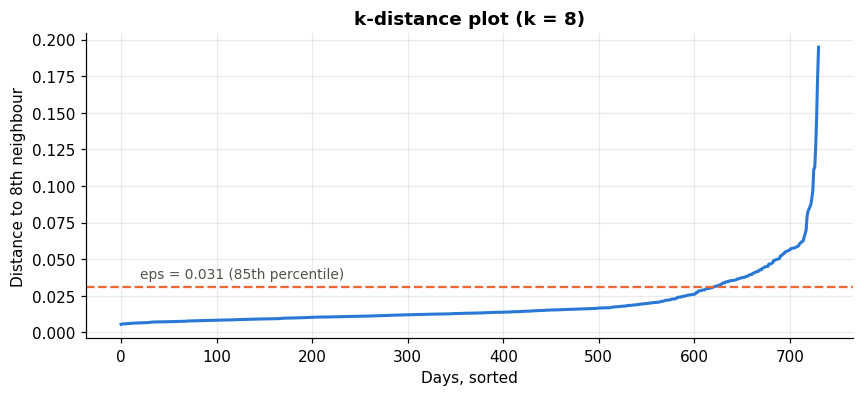

DBSCAN result (label -1 = noise): {-1: 78, 0: 212, 1: 441}


In [6]:
MIN_SAMPLES = 2 * X.shape[1]
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
EPS = float(np.quantile(kdist, 0.85))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(kdist, color=BLUE, linewidth=2)
ax.axhline(EPS, color=ORANGE, linewidth=1.5, linestyle="--")
ax.annotate(f"eps = {EPS:.3f} (85th percentile)", (20, EPS), xytext=(0, 6), textcoords="offset points",
            color="#52514e", fontsize=9)
ax.set(title=f"k-distance plot (k = {MIN_SAMPLES})", xlabel="Days, sorted", ylabel=f"Distance to {MIN_SAMPLES}th neighbour")
plt.show()

db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
values, counts = np.unique(db.labels_, return_counts=True)
print("DBSCAN result (label -1 = noise):", dict(zip(values.tolist(), counts.tolist())))

**Result.** DBSCAN finds the same two dense regions (working days and days off) and labels the remaining days as **noise**. It cannot separate the finer day types, because they touch each other without a low-density gap between them. Its value for this project is the noise label: days that do not belong to any dense region are anomaly candidates, and they are compared with the other detectors in Step 7.

The choice of eps at the 85th percentile of the k-distances is a judgement call where the curve starts to rise steeply; a smaller eps labels more days as noise.

## 5. Comparing the methods and choosing one

In [7]:
gmm = fits[0]
candidates = {
    "k-means, k = 2": km_models[2].labels_,
    "k-means, k = 5": km_models[5].labels_,
    "Ward, k = 5": AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(X),
    f"GMM full, k = {best_k}": gmm.predict(X),
    "DBSCAN": db.labels_,
}
summary = pd.DataFrame({
    name: {"clusters": len(set(lab) - {-1}),
           "silhouette": round(silhouette_score(X[lab >= 0], lab[lab >= 0]), 3),
           "largest / smallest": f"{np.bincount(lab[lab >= 0]).max()} / {np.bincount(lab[lab >= 0]).min()}"}
    for name, lab in candidates.items()}).T
agreement = pd.DataFrame({a: {b: adjusted_rand_score(la, lb) for b, lb in candidates.items()}
                          for a, la in candidates.items()}).round(2)
display(summary)
display(agreement)

,clusters,silhouette,largest / smallest
"k-means, k = 2",2,0.668,492 / 239
"k-means, k = 5",5,0.259,256 / 25
"Ward, k = 5",5,0.349,232 / 35
"GMM full, k = 5",5,0.248,235 / 29
DBSCAN,2,0.739,441 / 212


,"k-means, k = 2","k-means, k = 5","Ward, k = 5","GMM full, k = 5",DBSCAN
"k-means, k = 2",1.00,0.43,0.41,0.40,0.77
"k-means, k = 5",0.43,1.00,0.51,0.43,0.44
"Ward, k = 5",0.41,0.51,1.00,0.50,0.45
"GMM full, k = 5",0.40,0.43,0.50,1.00,0.53
DBSCAN,0.77,0.44,0.45,0.53,1.00


**Choice: GMM with 5 components and full covariance**, for four reasons:

1. **BIC selects it** among all GMM settings (Section 3).
2. **It is stable** across random starts.
3. **It gives probabilities, not just labels.** Each day gets a probability of belonging to each day type, and an overall likelihood under the model. A day with a very low likelihood fits no day type well, which is directly usable as an anomaly score in Step 7 (Anomaly Detection 1, Slides 32 to 34).
4. **Full covariance allows day types of different sizes and shapes** (Clustering, Slides 118 and 123), which matters here: the rainy-day groups are much smaller and more spread out than the normal working-day group. k-means assumes round clusters of similar size.

The silhouette score prefers k = 2. That is expected: silhouette rewards clusters with clear gaps between them, and the finer day types overlap. The interpretation in the next section shows whether these overlapping types are real.

**A limitation to report.** All methods agree on the main split (working days versus days off), but the 5-cluster solutions of k-means, Ward and GMM agree only moderately with each other (adjusted Rand index about 0.4 to 0.5). The finer structure is therefore partly method-dependent. The GMM solution is preferred for the reasons above, not because it is the only possible answer.

## 6. What are the five day types?

Each cluster is described by its **average 24-hour shape** and by attributes from `day_info.csv` that were **not** used in the clustering. If the clusters line up with these attributes in a sensible way, they are meaningful day types (expert knowledge, Slide 114).

In [8]:
labels = pd.Series(gmm.predict(X), index=Z.index, name="cluster")
day = info.assign(cluster=labels, level=level.level_all,
                  morning_share=shape[["h07", "h08", "h09"]].sum(axis=1),
                  evening_share=shape[["h17", "h18", "h19"]].sum(axis=1))
profile = day.groupby("cluster").agg(
    days=("total", "size"),
    working_day=("workingday", "mean"),
    holiday=("holiday", "mean"),
    mean_temp_c=("temp_c_mean", "mean"),
    bad_weather_hours=("bad_weather_daytime_hours", "mean"),
    casual_share=("casual_share", "mean"),
    level=("level", "mean"),
    morning_share=("morning_share", "mean"),
    evening_share=("evening_share", "mean"),
)

# Name each cluster from its profile with explicit rules, so the names do not depend on
# the arbitrary cluster numbers that the GMM assigns.
def name_cluster(row):
    kind = "working day" if row.working_day > 0.5 else "day off"
    if row.bad_weather_hours > 2.5:
        return f"Rainy {kind}"
    if kind == "working day":
        return "Warm working day" if row.mean_temp_c >= 16 else "Cool working day"
    return "Normal day off"

profile["name"] = profile.apply(name_cluster, axis=1)
assert profile.name.is_unique, "Two clusters received the same name; check the naming rules."
names = labels.map(profile.name).rename("day_type")

ORDER = ["Cool working day", "Warm working day", "Rainy working day", "Normal day off", "Rainy day off"]
COLORS = dict(zip(ORDER, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
profile = profile.reset_index().set_index("name").loc[ORDER]
profile.style.format({"working_day": "{:.0%}", "holiday": "{:.0%}", "mean_temp_c": "{:.1f}",
                      "bad_weather_hours": "{:.1f}", "casual_share": "{:.0%}", "level": "{:+.2f}",
                      "morning_share": "{:.0%}", "evening_share": "{:.0%}"})

,cluster,days,working_day,holiday,mean_temp_c,bad_weather_hours,casual_share,level,morning_share,evening_share
name,,,,,,,,,,
Cool working day,1,169,99%,1%,12.1,0.6,12%,+0.02,23%,28%
Warm working day,4,235,100%,0%,19.1,0.5,13%,+0.01,21%,31%
Rainy working day,3,98,95%,4%,13.2,4.4,10%,-0.45,23%,27%
Normal day off,0,200,1%,4%,14.7,0.6,30%,-0.01,7%,19%
Rainy day off,2,29,10%,21%,13.1,5.1,25%,-1.06,9%,16%


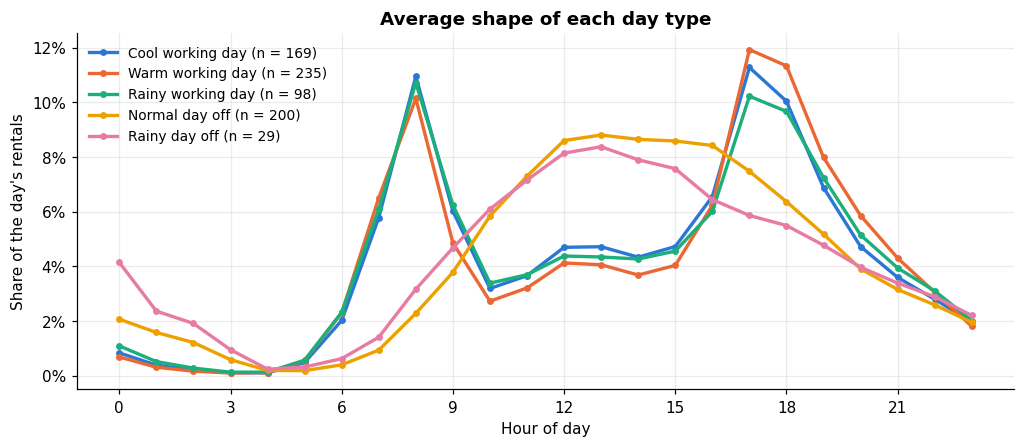

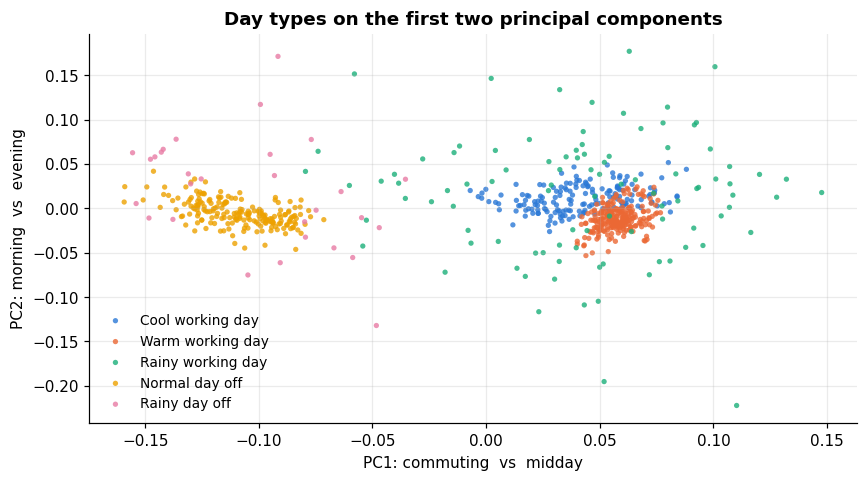

col_0,in a dense region,DBSCAN noise
day_type,,
Cool working day,169,0
Warm working day,235,0
Rainy working day,37,61
Normal day off,200,0
Rainy day off,12,17


In [9]:
fig, ax = plt.subplots(figsize=(11, 4.2))
hours = np.arange(24)
for name in profile.index:
    days = names[names == name].index
    ax.plot(hours, shape.loc[days].mean(), color=COLORS[name], linewidth=2.2, marker="o", markersize=3.5,
            label=f"{name} (n = {len(days)})")
ax.set(title="Average shape of each day type", xlabel="Hour of day", ylabel="Share of the day's rentals",
       xticks=range(0, 24, 3))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.6))
for name in profile.index:
    sel = names == name
    ax.scatter(Z.PC1[sel], Z.PC2[sel], s=12, color=COLORS[name], alpha=0.8, edgecolors="none", label=name)
ax.set(title="Day types on the first two principal components", xlabel="PC1: commuting  vs  midday",
       ylabel="PC2: morning  vs  evening")
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.show()

pd.crosstab(names, db.labels_ == -1).rename(columns={False: "in a dense region", True: "DBSCAN noise"}).loc[ORDER]

**Reading the five day types.**

- **Cool working day** and **warm working day:** both have the two commuting peaks. On warm days a larger share of riding happens in the evening, after work.
- **Rainy working day:** about 4 hours of daytime rain or snow on average, and demand well below that of similar nearby days. Its *average* shape is almost the same as a cool working day (about 23% of rentals at 7 to 9 and 27% at 17 to 19 in both), but **individual rainy days vary much more**: rain disrupts the pattern in a different way each time, depending on when it falls. The GMM captures these days as a wide, spread-out component around the normal working days.
- **Normal day off:** weekends and holidays with one broad midday block and a high casual share.
- **Rainy day off:** days off with about 5 hours of daytime rain; demand is roughly half that of similar nearby days, holidays are over-represented, and, as with rainy working days, the individual shapes vary widely.

This matches DBSCAN: every day DBSCAN labelled as noise falls into one of the two rainy types (see the table below). Rainy days are the irregular days around the dense cores of normal riding.

**Why this matters for the research question.** The calendar knows only "working day" and "day off". The data found **five** types, and two of them are defined by weather rather than by the calendar. A calendar context would compare a rainy working day with all other working days and might call it an anomaly. A learned context compares it with other rainy working days, where it is normal. Only days that are unusual *even for their own type* remain anomalies, which is what Step 7 tests.

One consequence to state in the report: ordinary rain becomes "normal" under learned contexts. The calendar baseline in Step 7 includes the weather situation for the same reason, so the comparison stays fair.

## 7. Rider groups: do casual and registered riders have the same day types?

The same GMM and BIC procedure is applied to each rider group's PCA scores (Step 4: 4 components for registered, 12 for casual).

In [10]:
group_models, group_bic = {}, {}
for g in ["registered", "casual"]:
    Zg = pd.read_csv(f"pca_scores_{g}.csv", index_col="dteday", parse_dates=True).values
    b = {k: GaussianMixture(k, covariance_type="full", n_init=5, random_state=SEED).fit(Zg).bic(Zg) for k in range(1, 8)}
    k_best = min(b, key=b.get)
    group_bic[g] = b
    group_models[g] = (GaussianMixture(k_best, covariance_type="full", n_init=10, random_state=SEED).fit(Zg), Zg)
    print(f"{g:10s}: lowest BIC at k = {k_best}")

pd.DataFrame(group_bic).rename_axis("components").round(0)

registered: lowest BIC at k = 5


casual    : lowest BIC at k = 2


,registered,casual
components,,
1,-12298.0,-44342.0
2,-13679.0,-45020.0
3,-14399.0,-44925.0
4,-14567.0,-44586.0
5,-14583.0,-44362.0
6,-14569.0,-44008.0
7,-14499.0,-43538.0


**Result.** Registered riders support the same number of day types as all riders, which is expected since they make up most rentals. **Casual riders support only about two**, in line with Step 4: their days vary a lot, but not in a few repeatable patterns. For the second research question this means casual anomalies are judged against broader, less specific contexts, which should be kept in mind when interpreting them.

## 8. Save

In [11]:
out = pd.DataFrame({"cluster": labels, "day_type": names})
probs = gmm.predict_proba(X)
for c in range(probs.shape[1]):
    out[f"p_cluster_{c}"] = probs[:, c]
out["log_likelihood"] = gmm.score_samples(X)
out["dbscan_label"] = db.labels_
out.to_csv("clusters_all.csv")

for g, (model, Zg) in group_models.items():
    pd.DataFrame({"cluster": model.predict(Zg), "log_likelihood": model.score_samples(Zg)},
                 index=Z.index).to_csv(f"clusters_{g}.csv")

print(out.day_type.value_counts().to_string())
print("Saved clusters_all.csv, clusters_registered.csv, clusters_casual.csv")

day_type
Warm working day     235
Normal day off       200
Cool working day     169
Rainy working day     98
Rainy day off         29
Saved clusters_all.csv, clusters_registered.csv, clusters_casual.csv


## Summary for the report

- Four clustering methods were compared on the 4 principal components of the day shapes.
- **All methods find the main split** between working days and days off (k-means silhouette 0.67 at k = 2).
- **GMM with full covariance and 5 components has the lowest BIC** and is stable across random starts. It was chosen because it also gives probabilities and likelihoods, which Step 7 uses as an anomaly score.
- The five day types are **cool working days, warm working days, rainy working days, normal days off and rainy days off**. Two of the five are defined by weather, which the calendar labels cannot express.
- The two rainy types have nearly normal average shapes but much more day-to-day variation; all DBSCAN noise days fall into them. Average linkage isolates a handful of days that resemble no other day; these are anomaly candidates for Step 7.
- The 5-cluster solutions of different methods agree only moderately (adjusted Rand index about 0.4 to 0.5), so the finer structure is partly method-dependent.
- Registered riders show the same structure; casual riders support only about two day types.

**Next:** Step 6, feature engineering, then Step 7, anomaly scoring and evaluation against the verified events.